## 4. EDA (Exploratory Data Analysis)

1. Loading
2. Daily demand profile
3. Weekly rhythm
4. Temeperature and demand
5. Embedded solar story
6. Bank holidays and the calendar
7. Volatility (which slots are hardest to predict)
8. Findings

### 1. Loading & config

In [1]:
import sqlite3    
from pathlib import Path   
import pandas as pd   
import numpy as np   
import matplotlib.pyplot as plt   
import matplotlib.dates as mdates   

CWD=Path.cwd()
PROJECT_ROOT= CWD.parent if CWD.name=="notebooks" else CWD
DB_PATH=PROJECT_ROOT / "database" / "energy.db"
FIG_DIR=PROJECT_ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)

conn=sqlite3.connect(DB_PATH)

#Loading model_features_tbl table
df=pd.read_sql_query("SELECT * FROM model_features_tbl;", conn)
df["date"]= pd.to_datetime(df["settlement_date"])

print(f"{len(df):,} rows x {df.shape[1]} columns")
print(f"Period: {df['settlement_date'].min()} to {df['settlement_date'].max()}")


# Plot styles
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi":200,
    "savefig.bbox":"tight",
    "font.size":10,
    "axes.titlesize":12,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid":True,
    "grid.alpha":0.25,
    "figure.facecolor": "white",

})

# Colour palette
C = {"winter": "#2166AC", "spring": "#66A61E", "summer": "#D95F02",
     "autumn": "#8C6D31", "primary": "#1B4965", "accent": "#D95F02",
     "muted": "#9E9E9E"}

def save(fig, name):
    path=FIG_DIR / f"{name}.png"
    fig.savefig(path)
    print(f" Saved: figures/{name}.png")
    

51,258 rows x 50 columns
Period: 2023-01-29 to 2025-12-31


In [2]:
# Pre-check before plotting
print("TSD (MW) summary")
print(df["tsd_mw"].describe().round(0).to_string())

print("\nAnnual means - trend")
print(df.groupby("year")["tsd_mw"].agg(["mean", "min", "max"]).round(0).to_string())

print("\nRows per season:")
print(df["season"].value_counts().to_string())

TSD (MW) summary
count    51258.0
mean     28115.0
std       5808.0
min      15297.0
25%      23703.0
50%      27022.0
75%      31612.0
max      47760.0

Annual means - trend
         mean      min      max
year                           
2023  27501.0  16513.0  46863.0
2024  28233.0  17138.0  47507.0
2025  28564.0  15297.0  47760.0

Rows per season:
season
Summer    13248
Spring    13242
Autumn    13104
Winter    11664


### 2. Daily demand profile

 Saved: figures/1_daily_profile_by_season.png


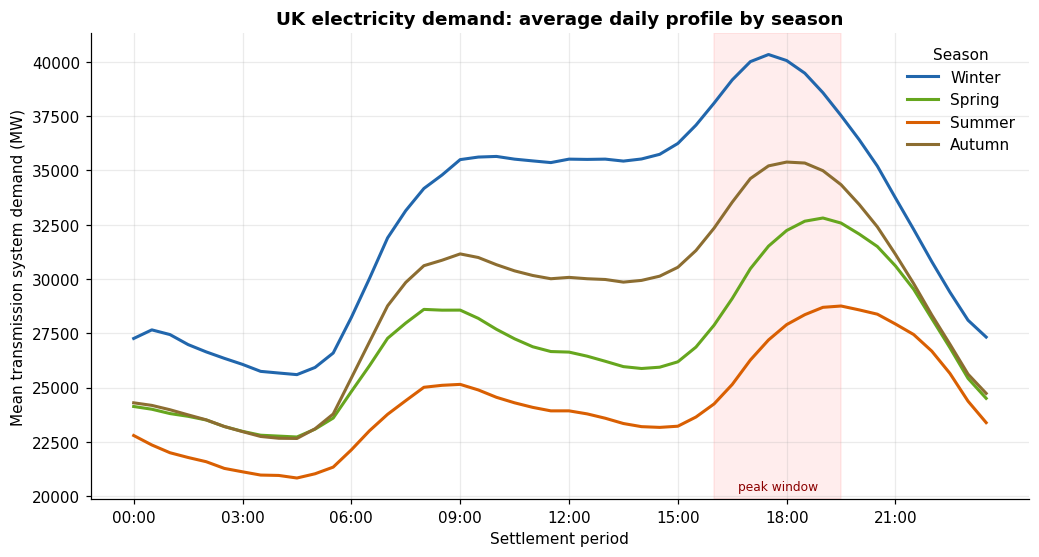

In [3]:
fig,ax=plt.subplots(figsize=(11, 5.5))

for season, colour in [("Winter", C["winter"]), ("Spring", C["spring"]),
                       ("Summer", C["summer"]), ("Autumn", C["autumn"])]:
    prof=(df[df["season"]==season]
          .groupby("settlement_period")["tsd_mw"].mean())
    ax.plot(prof.index, prof.values, label=season, color=colour, linewidth=2)

ax.set_xlabel("Settlement period")
ax.set_ylabel("Mean transmission system demand (MW)")
ax.set_title("UK electricity demand: average daily profile by season")

#Labeling the x-axis in clock time rather than period number
ticks=range(1,49,6)
ax.set_xticks(list(ticks))
ax.set_xticklabels([f"{(t-1)//2:02d}:{'30' if (t-1)%2 else '00'}" for t in ticks])

ax.axvspan(33,40, alpha=0.07, color="red")
ax.text(36.5, ax.get_ylim()[0] +400, "peak window", ha="center",
        fontsize=8, color="darkred")
ax.legend(title="Season", frameon=False)

save(fig, "1_daily_profile_by_season")
plt.show()

    

### 3. Weekly heatmap - demand by day of week and time of day




 Saved: figures/2_weekly_heatmap.png


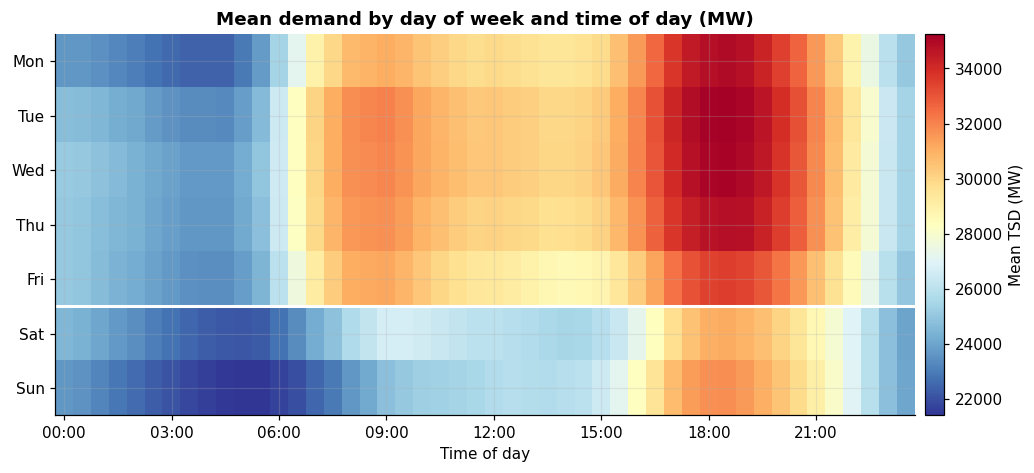

In [4]:
pivot=(df.pivot_table(index="day_of_week", columns="settlement_period",
                      values="tsd_mw", aggfunc="mean")
                      .reindex(range(7)))

fig,ax=plt.subplots(figsize=(12,4.5))
im= ax.imshow(pivot.values, aspect="auto", cmap="RdYlBu_r", interpolation="nearest")

ax.set_yticks(range(7))
ax.set_yticklabels(["Mon", "Tue","Wed", "Thu", "Fri", "Sat", "Sun"])
ticks=list(range(0,48,6))
ax.set_xticks(ticks)
ax.set_xticklabels([f"{t//2:02d}:00" for t in ticks])
ax.set_xlabel("Time of day")
ax.set_title("Mean demand by day of week and time of day (MW)")

#Separator between working week and weekend
ax.axhline(4.5, color="white", linewidth=2)

fig.colorbar(im, ax=ax, label="Mean TSD (MW)", pad=0.01)
save(fig, "2_weekly_heatmap")
plt.show()

### 4. Temperature and demand

 Saved: figures/3_temperature_vs_demand.png


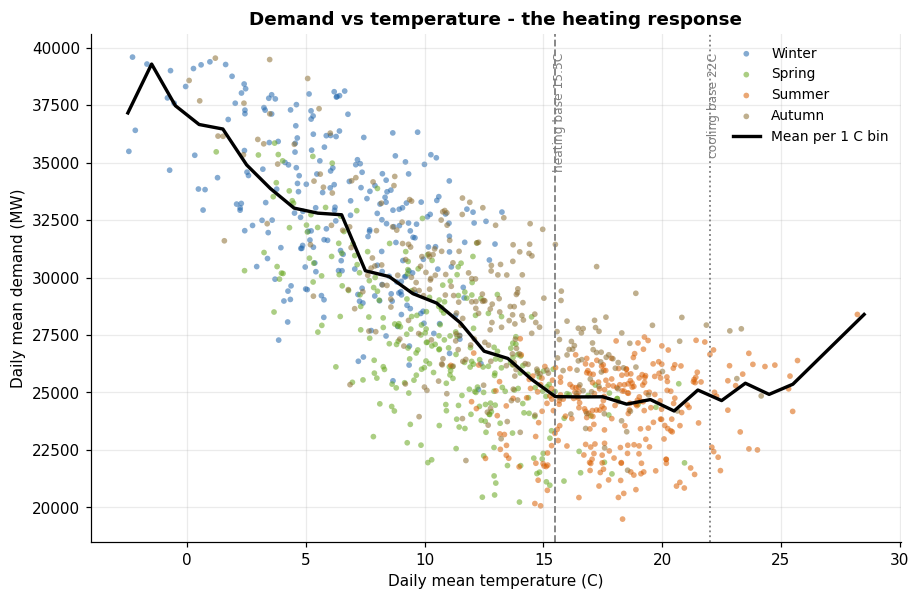

In [5]:
daily=(df.groupby("settlement_date").agg(tsd_mw=("tsd_mw", "mean"),
                                         temperature_c=("temperature_c", "mean"),
                                         season=("season", "first"),
                                         is_working_day=("is_working_day", "first"))
                                         .reset_index())

fig,ax=plt.subplots(figsize=(9.5,6))

for season, colour in [("Winter", C["winter"]), ("Spring", C["spring"]),
                       ("Summer", C["summer"]), ("Autumn", C["autumn"])]:
    s=daily[daily["season"]==season]
    ax.scatter(s["temperature_c"], s["tsd_mw"], s=14, alpha=0.55,
               color=colour, label=season, edgecolors="none")


#LOWESS-style trend without extra dependencies: mean demand per 1 C bin
bins=np.arange(np.floor(daily["temperature_c"].min()),
               np.ceil(daily["temperature_c"].max()) +1, 1.0)
binned=(daily.groupby(pd.cut(daily["temperature_c"], bins), observed=True)["tsd_mw"]
        .mean().dropna())
centres=[iv.mid for iv in binned.index]

ax.plot(centres, binned.values, color="black", linewidth=2.2,
        label="Mean per 1 C bin", zorder=5)

#The 2 degreee-day thresholds 
ax.axvline(15.5, color="gray", linestyle="--", linewidth=1.2)
ax.axvline(22.0, color="gray", linestyle=":", linewidth=1.2)
ax.text(15.4, ax.get_ylim()[1]*0.98, "heating base 15.5C", fontsize=8,
        rotation=90, va="top", color="gray")
ax.text(21.9, ax.get_ylim()[1]*0.98, "cooling base 22C", fontsize=8,
        rotation=90, va="top", color="gray")



ax.set_xlabel("Daily mean temperature (C)")
ax.set_ylabel("Daily mean demand (MW)")
ax.set_title("Demand vs temperature - the heating response")
ax.legend(frameon=False, fontsize=9)
save(fig, "3_temperature_vs_demand")
plt.show()

    

In [6]:
#Quantifying  both arms of the "V" to see if the cooling side is real
cold = daily[daily["temperature_c"] < 15.5]
warm = daily[daily["temperature_c"] > 18.0]

print("HEATING ARM (below 15.5 C)")
print(f"  days                         : {len(cold):,}")
print(f"  correlation temp vs demand   : {cold['temperature_c'].corr(cold['tsd_mw']):.3f}")

print("\nCOOLING ARM (above 18 C)")
print(f"  days                         : {len(warm):,}")
if len(warm) > 30:
    print(f"  correlation temp vs demand   : {warm['temperature_c'].corr(warm['tsd_mw']):.3f}")
else:
    print("  too few days to say anything reliable")

print(f"\nHalf-hourly rows with cooling_degrees > 0 : "
      f"{(df['cooling_degrees'] > 0).sum():,} of {len(df):,} "
      f"({(df['cooling_degrees'] > 0).mean():.2%})")
print(f"Days above 22 C (daily mean)             : "
      f"{(daily['temperature_c'] > 22).sum()}")

HEATING ARM (below 15.5 C)
  days                         : 753
  correlation temp vs demand   : -0.731

COOLING ARM (above 18 C)
  days                         : 174
  correlation temp vs demand   : 0.166

Half-hourly rows with cooling_degrees > 0 : 2,766 of 51,258 (5.40%)
Days above 22 C (daily mean)             : 29


### 5. Summer daytime demand: measured vs underlying

Behind-the-meter solar generation (rooftop solar capacity) does not appear on the transmission system as generation --> it
appears as 'absent demand'. 
Using `underlying_demand_mw` to add embedded generation back to reconstruct what the demand curve would have looked like
without it.

 Saved: figures/4_embedded_solar_effect.png


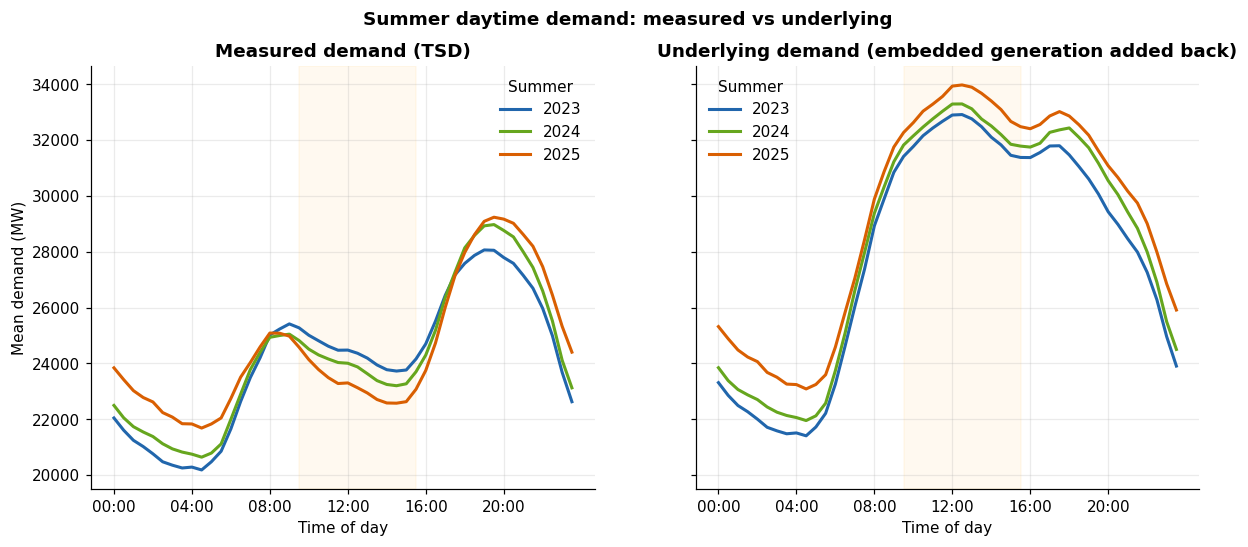

In [7]:
summer=df[df["season"]=="Summer"]

fig,axes=plt.subplots(1,2, figsize=(13,5), sharey=True)

#Left: measured demand , by year
for year, colour in zip(sorted(summer["year"].unique()),
                        [C["winter"], C["spring"], C["accent"]]):
    p=summer[summer["year"]==year].groupby("settlement_period")["tsd_mw"].mean()
    axes[0].plot(p.index, p.values, label=str(year), color=colour, linewidth=2)
axes[0].set_title("Measured demand (TSD)")
axes[0].set_ylabel("Mean demand (MW)")


#Right: demand with embedded generation added back
for year, colour in zip(sorted(summer["year"].unique()),
                        [C["winter"], C["spring"], C["accent"]]):
    p=summer[summer["year"]==year].groupby("settlement_period")["underlying_demand_mw"].mean()
    axes[1].plot(p.index, p.values, label=str(year), color=colour, linewidth=2)
axes[1].set_title("Underlying demand (embedded generation added back)")


for ax in axes:
    ticks=range(1,49,8)
    ax.set_xticks(list(ticks))
    ax.set_xticklabels([f"{(t-1)//2:02d}:00" for t in ticks])
    ax.set_xlabel("Time of day")
    ax.legend(frameon=False, title="Summer")
    ax.axvspan(20,32, alpha=0.06, color="orange")

fig.suptitle("Summer daytime demand: measured vs underlying", fontweight="bold")
save(fig, "4_embedded_solar_effect")
plt.show()



    

In [8]:
#Quantifying the midday suppression

midday=df[(df["settlement_period"].between(20,32)) & (df["season"]=="Summer")]

tbl=(midday.groupby("year").agg(measured_tsd=("tsd_mw", "mean"),
                                embedded_solar=("embedded_solar_mw", "mean"),
                                underlying=("underlying_demand_mw", "mean" ))
                            .round(0))
tbl["solar_share_of_underlying"]=(tbl["embedded_solar"] / tbl["underlying"]).map("{:.1%}".format)

print("Summer midday (10:00-16:00), by year:")
print(tbl.to_string())

first,last=tbl.index.min(), tbl.index.max()
d_meas=tbl.loc[last, "measured_tsd"] - tbl.loc[first, "measured_tsd"]
d_under=tbl.loc[last, "underlying"] - tbl.loc[first, "underlying"]

print(f"\nChange {first} -> {last}:")
print(f" measured demand: {d_meas:+,.0f} MW")
print(f" underlying demand: {d_under:+,.0f} MW")

print("\nIf measured falls much faster than underlying, the decline is a")
print("measurement artefact of rising embedded solar, not falling consumption.")




Summer midday (10:00-16:00), by year:
      measured_tsd  embedded_solar  underlying solar_share_of_underlying
year                                                                    
2023       24356.0          6105.0     32178.0                     19.0%
2024       23860.0          6762.0     32545.0                     20.8%
2025       23250.0          8220.0     33227.0                     24.7%

Change 2023 -> 2025:
 measured demand: -1,106 MW
 underlying demand: +1,049 MW

If measured falls much faster than underlying, the decline is a
measurement artefact of rising embedded solar, not falling consumption.


### 6.Bank holiday demand shortfall


Bank holidays vs a typical weekday in the same month:
settlement_date  tsd_mw  expected  shortfall_pct
     2023-04-07 24505.1   27766.3          -11.7
     2023-04-10 24206.0   27766.3          -12.8
     2023-05-01 24050.0   25513.7           -5.7
     2023-05-08 24478.5   25513.7           -4.1
     2023-05-29 20445.4   25513.7          -19.9
     2023-08-28 23391.8   25262.2           -7.4
     2023-12-25 25127.1   33790.8          -25.6
     2023-12-26 26357.1   33790.8          -22.0
     2024-01-01 27691.8   35710.1          -22.5
     2024-03-29 26459.4   31051.8          -14.8
     2024-04-01 25534.8   27766.3           -8.0
     2024-05-06 24870.6   25513.7           -2.5
     2024-05-27 22605.3   25513.7          -11.4
     2024-08-26 23371.6   25262.2           -7.5
     2024-12-25 26191.7   33790.8          -22.5
     2024-12-26 26541.8   33790.8          -21.5
     2025-01-01 28389.7   35710.1          -20.5
     2025-04-18 24449.1   27766.3          -11.9
     2025-04-21

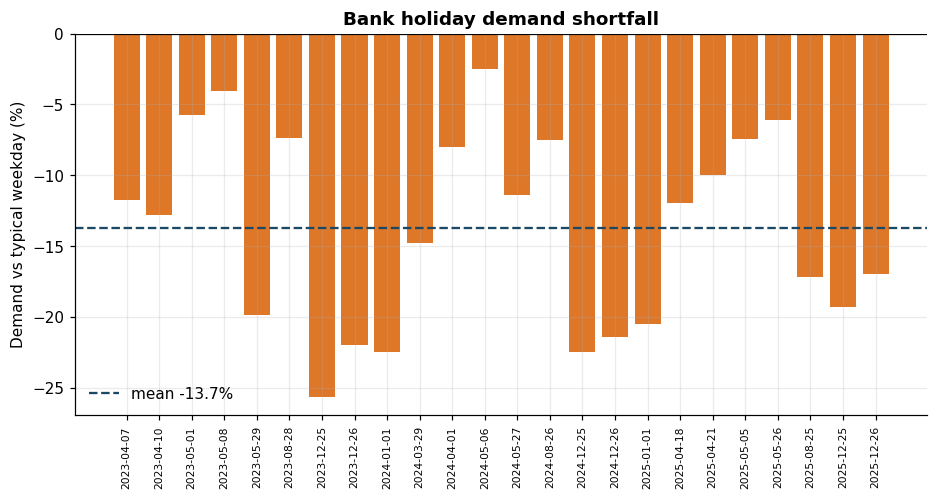

In [9]:
daily_full=(df.groupby("settlement_date")
            .agg(tsd_mw=("tsd_mw", "mean"),
                 is_bank_holiday=("is_bank_holiday", "first"),
                 is_weekend=("is_weekend", "first"),
                 day_of_week=("day_of_week", "first"),
                 month=("month", "first"))
            .reset_index())

#Comparing against ordinary weekdays in the same month (bank holidays are almost all weekdays)
weekday=daily_full[daily_full["day_of_week"] < 5]
bh=weekday[weekday["is_bank_holiday"]==1]
norm=weekday[weekday["is_bank_holiday"]==0]

monthly_norm=norm.groupby("month")["tsd_mw"].mean()
bh=bh.assign(expected=bh["month"].map(monthly_norm))
bh=bh.assign(shortfall_pct=(bh["tsd_mw"] / bh["expected"] -1) *100)

print("Bank holidays vs a typical weekday in the same month:")
print(bh[["settlement_date", "tsd_mw", "expected", "shortfall_pct"]]
      .round(1).to_string(index=False))
print(f"\nMean shortfall: {bh['shortfall_pct'].mean():.1f}%")

fig,ax=plt.subplots(figsize=(10,4.5))
ax.bar(range(len(bh)), bh["shortfall_pct"], color=C["accent"], alpha=0.85)
ax.axhline(0, color="black", linewidth=0.8)
ax.axhline(bh["shortfall_pct"].mean(), color=C["primary"], linestyle="--",
           label=f"mean {bh['shortfall_pct'].mean():.1f}%")
ax.set_xticks(range(len(bh)))
ax.set_xticklabels(bh["settlement_date"], rotation=90, fontsize=7)
ax.set_ylabel("Demand vs typical weekday (%)")
ax.set_title("Bank holiday demand shortfall")
ax.legend(frameon=False)
save(fig, "5_bank_holiday_effect")
plt.show()




### 7. Demand level vs variability across the day


 Saved: figures/6_variability_by_period.png


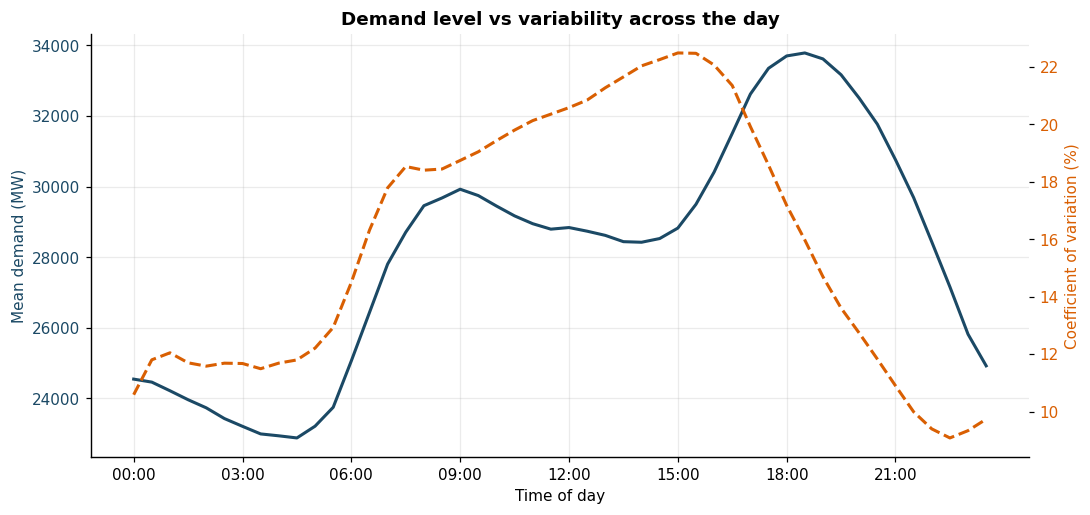

Most variable settlement_periods (highest CV):
                   mean_mw   sd_mw  cv_pct
settlement_period                         
31                 28821.6  6477.3    22.5
32                 29496.0  6625.1    22.5
30                 28525.8  6344.9    22.2
33                 30408.1  6706.2    22.1
29                 28420.6  6259.5    22.0

Least variable:
                   mean_mw   sd_mw  cv_pct
settlement_period                         
46                 27156.8  2466.0     9.1
47                 25814.6  2409.8     9.3
45                 28431.7  2671.3     9.4
48                 24919.3  2425.8     9.7
44                 29686.0  2965.4    10.0


In [10]:
vol =(df.groupby("settlement_period")
      .agg(mean_mw=("tsd_mw", "mean"), sd_mw=("tsd_mw", "std"))
      .assign(cv_pct=lambda x: x["sd_mw"] / x["mean_mw"]*100))

fig,ax1=plt.subplots(figsize=(11,5))
ax1.plot(vol.index, vol["mean_mw"], color=C["primary"], linewidth=2, label="Mean demand")
ax1.set_ylabel("Mean demand (MW)", color=C["primary"])
ax1.tick_params(axis="y", labelcolor=C["primary"])
ax1.set_xlabel("Time of day")
ticks=range(1,49,6)
ax1.set_xticks(list(ticks))
ax1.set_xticklabels([f"{(t-1)//2:02d}:00" for t in ticks])

ax2=ax1.twinx()
ax2.plot(vol.index, vol["cv_pct"], color=C["accent"], linewidth=2,
         linestyle="--", label="Variability (CV %)")
ax2.set_ylabel("Coefficient of variation (%)", color=C["accent"])
ax2.tick_params(axis="y", labelcolor=C["accent"])
ax2.grid(False)

ax1.set_title("Demand level vs variability across the day")
save(fig, "6_variability_by_period")
plt.show()

print("Most variable settlement_periods (highest CV):")
print(vol.sort_values("cv_pct", ascending=False).head(5).round(1).to_string())
print("\nLeast variable:")
print(vol.sort_values("cv_pct").head(5).round(1).to_string())


### 8. Summary

In [11]:
peak_p=df.groupby("settlement_period")["tsd_mw"].mean().idxmax()
trough_p=df.groupby("settlement_period")["tsd_mw"].mean().idxmin()
to_clock=lambda p: f"{(p-1)//2:02d}:{'30' if (p-1)%2 else '00'}"

wd=df.groupby("is_working_day")["tsd_mw"].mean()
win=df[df["season"] =="Winter"]["tsd_mw"].mean()
sum_=df[df["season"]=="Summer"]["tsd_mw"].mean()

print("Key findings")
print("-" *40)

print(f"1. Peak demand slot:        {to_clock(peak_p)} (period {peak_p})")
print(f"   Trough slot:             {to_clock(trough_p)} (period {trough_p})")
print(f"2. Working vs non-working:  {wd.get(1,0):,.0f} vs {wd.get(0,0):,.0f} MW "
      f"({(wd.get(1,0)/wd.get(0,1)-1):.1%})")
print(f"3. Winter vs summer:        {win:,.0f} vs {sum_:,.0f} MW "
      f"({(win/sum_-1):.1%})")
print(f"4. Cooling_degree coverage: {(df['cooling_degrees']>0).mean():.2%} of rows")
print(f"5. Bank holiday shortfall:  {bh['shortfall_pct'].mean():.1f}% vs typical weekday")


Key findings
----------------------------------------
1. Peak demand slot:        18:30 (period 38)
   Trough slot:             04:30 (period 10)
2. Working vs non-working:  29,175 vs 25,733 MW (13.4%)
3. Winter vs summer:        32,840 vs 24,279 MW (35.3%)
4. Cooling_degree coverage: 5.40% of rows
5. Bank holiday shortfall:  -13.7% vs typical weekday
